*  DSC640-T302 Data Presentation & Visualization (2267-1)
*  Weeks 5 & 6 Assignment - Kia Thefts
*  David Jorgensen

# Weeks 5 & 6 Assignment - Kia Thefts

Datasets:
- `data/KiaHyundaiMilwaukeeData.csv`
- `data/carTheftsMap.csv`
- `data/kiaHyundaiThefts.csv`
- `data/Motherboard VICE News Kia Hyundai Theft Data.xlsx`

Dataset Sources:
- [Motherboard VICE News Kia Hyundai Theft Data](https://docs.google.com/spreadsheets/d/1-6614t_Ata5k7oESrm-HAdF1uOe8aPGRaQECl44GYeE/edit#gid=0)
- [Car thefts are rising. Is a TikTok challenge to blame?](https://usafacts.org/data-projects/car-thefts)

## The Story: Audience, Purpose, and Medium

**Audience:** Milwaukee area Kia and Hyundai owners, and the broader Milwaukee public; a general audience with little to no experience reading crime statistics, but a direct personal stake in the topic (their car, or their neighbor's, could be a target). I'm assuming low data literacy and no prior familiarity with the "Kia Boyz" story, so every chart leads with a plain language takeaway instead of an axis label.

**Purpose / Call to Action:** Many 2011-2022 Kia and Hyundai models were built without engine immobilizers and can be started with nothing but a USB cable in under 30 seconds, a method that went viral on TikTok as the "Kia Challenge" in 2021-2022. This is not a story about crime rising everywhere; it's a story about one specific, fixable vulnerability. The ask: **Milwaukee Kia/Hyundai owners should get the free anti-theft software update at any dealer and pick up a free steering-wheel lock from an MPD district station**, and the city should keep funding the lock giveaway because it directly targets the mechanism of the crime instead of crime in general.

**Medium:** A short, visual-first explainer designed to work as a social media carousel or a one page flyer handed out at a police district station. One idea and one headline per chart, readable in the time it takes to scroll past a post or wait in line.

In [1]:
# Setup
.libPaths(c(Sys.getenv("R_LIBS_USER"), .libPaths()))
suppressMessages({
  library(readr)
  library(readxl)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(scales)
  library(stringr)
})

theme_set(theme_minimal(base_size = 12))
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 150)

data_dir <- "data"

### Loading and Tidying the Four Provided Datasets

Three of the files are already tidy (one row per month/city). The fourth, the Motherboard/VICE workbook, stores every city as a 3-column block (`Kia/Hyundais`, `All`, `Percent`) with the city name written only once, above the first column of its block, and blank cells beside it. The code below forward-fills those blank city labels and reshapes the sheet into a normal long-format table before it's used in any chart.

In [ ]:
# ---- KiaHyundaiMilwaukeeData.csv : Milwaukee, monthly, 2019-2022 ----
milwaukee <- read_csv(file.path(data_dir, "KiaHyundaiMilwaukeeData.csv"), show_col_types = FALSE)

month_levels <- c("Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec")
milwaukee <- milwaukee %>%
  mutate(date = as.Date(paste(year, match(month, month_levels), "01", sep = "-")))

# ---- kiaHyundaiThefts.csv : 13 other tracked cities, monthly, 2019-2022 ----
other_cities <- read_csv(file.path(data_dir, "kiaHyundaiThefts.csv"), show_col_types = FALSE)

# ---- carTheftsMap.csv : nationwide agency-level totals, all makes, 2019 vs 2022 ----
national_map <- read_csv(file.path(data_dir, "carTheftsMap.csv"), show_col_types = FALSE)

# ---- Motherboard VICE workbook : ~70 cities, wide + irregular -> tidy long format ----
mb_path <- file.path(data_dir, "Motherboard VICE News Kia Hyundai Theft Data.xlsx")
raw <- suppressMessages(read_excel(mb_path, sheet = "Data", col_names = FALSE))

city_row   <- as.character(unlist(raw[1, ]))   # city name appears once per 3-column block
metric_row <- as.character(unlist(raw[2, ]))   # "Kia/Hyundais" / "All" / "Percent"
for (i in seq_along(city_row)) {
  if (i > 1 && is.na(city_row[i])) city_row[i] <- city_row[i - 1]  # forward-fill blank labels
}

body <- raw[-c(1, 2), ]
names(body) <- c("date", paste(city_row[-1], metric_row[-1], sep = "__"))

# Pivot to long format, filter for Kia/Hyundais, and convert values to numeric
motherboard_long <- body %>%
  mutate(date = as.Date(date)) %>%
  pivot_longer(-date, names_to = c("city", "metric"), values_to = "value", names_sep = "__") %>%
  filter(!is.na(city), metric == "Kia/Hyundais") %>%
  mutate(value = suppressWarnings(as.numeric(value))) %>%
  select(date, city, kia_hyundai_thefts = value) %>%
  filter(!is.na(date))

# Summarize total Kia/Hyundai thefts by city
city_totals <- motherboard_long %>%
  group_by(city) %>%
  summarise(total = sum(kia_hyundai_thefts, na.rm = TRUE), .groups = "drop") %>%
  arrange(desc(total))

# Print row counts for each dataset
cat("Milwaukee rows:", nrow(milwaukee),
    "| Other-city rows:", nrow(other_cities),
    "| National agencies:", nrow(national_map),
    "| Motherboard cities:", n_distinct(motherboard_long$city), "\n")

Milwaukee rows: 48 | Other-city rows: 552 | National agencies: 556 | Motherboard cities: 70 


### Visual 1, Pie Chart: The National Backdrop

Before zooming into Kia/Hyundai specifically, it's worth showing the backdrop: overall car theft climbed at most U.S. police agencies after 2019. This is not a Milwaukee-only story, or even purely a Kia/Hyundai story, as it sits inside a bigger national trend (`carTheftsMap.csv`).

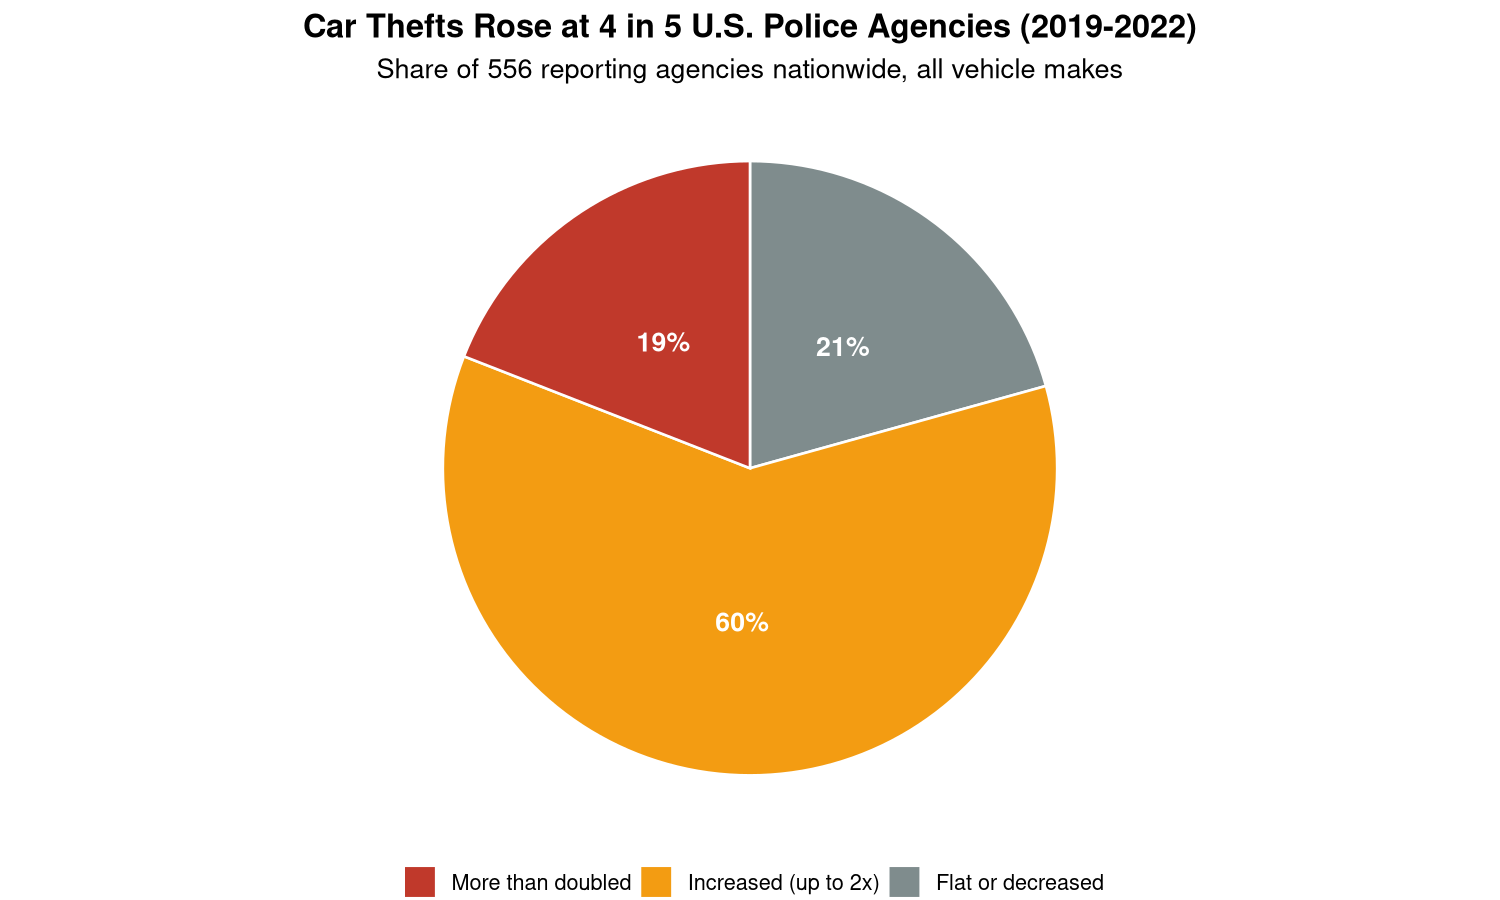

In [ ]:
# Create a new column to categorize the percent change from 2019 to 2022
pie_df <- national_map %>%
  mutate(bucket = case_when(
    percentChange2019to2022 > 1  ~ "More than doubled",
    percentChange2019to2022 > 0  ~ "Increased (up to 2x)",
    TRUE                          ~ "Flat or decreased"
  )) %>%
  count(bucket) %>%
  mutate(bucket = factor(bucket, levels = c("More than doubled", "Increased (up to 2x)", "Flat or decreased")),
         pct = n / sum(n))

# Create the pie chart
p1 <- ggplot(pie_df, aes(x = "", y = n, fill = bucket)) +
  geom_col(width = 1, color = "white") +
  coord_polar(theta = "y") +
  scale_fill_manual(values = c("More than doubled" = "#C0392B",
                                "Increased (up to 2x)" = "#F39C12",
                                "Flat or decreased" = "#7F8C8D")) +
  geom_text(aes(label = percent(pct, accuracy = 1)), position = position_stack(vjust = 0.5),
            color = "white", fontface = "bold", size = 4.5) +
  labs(title = "Car Thefts Rose at 4 in 5 U.S. Police Agencies (2019-2022)",
       subtitle = "Share of 556 reporting agencies nationwide, all vehicle makes", fill = NULL) +
  theme_void(base_size = 13) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5),
        plot.subtitle = element_text(hjust = 0.5),
        legend.position = "bottom")
p1

### Visual 2, Donut Chart: Milwaukee's 2022 Snapshot

Zooming into Milwaukee: Kia and Hyundai are a small share of the cars on the road, but by 2022 they accounted for the majority of all reported car thefts in the city (`KiaHyundaiMilwaukeeData.csv`).

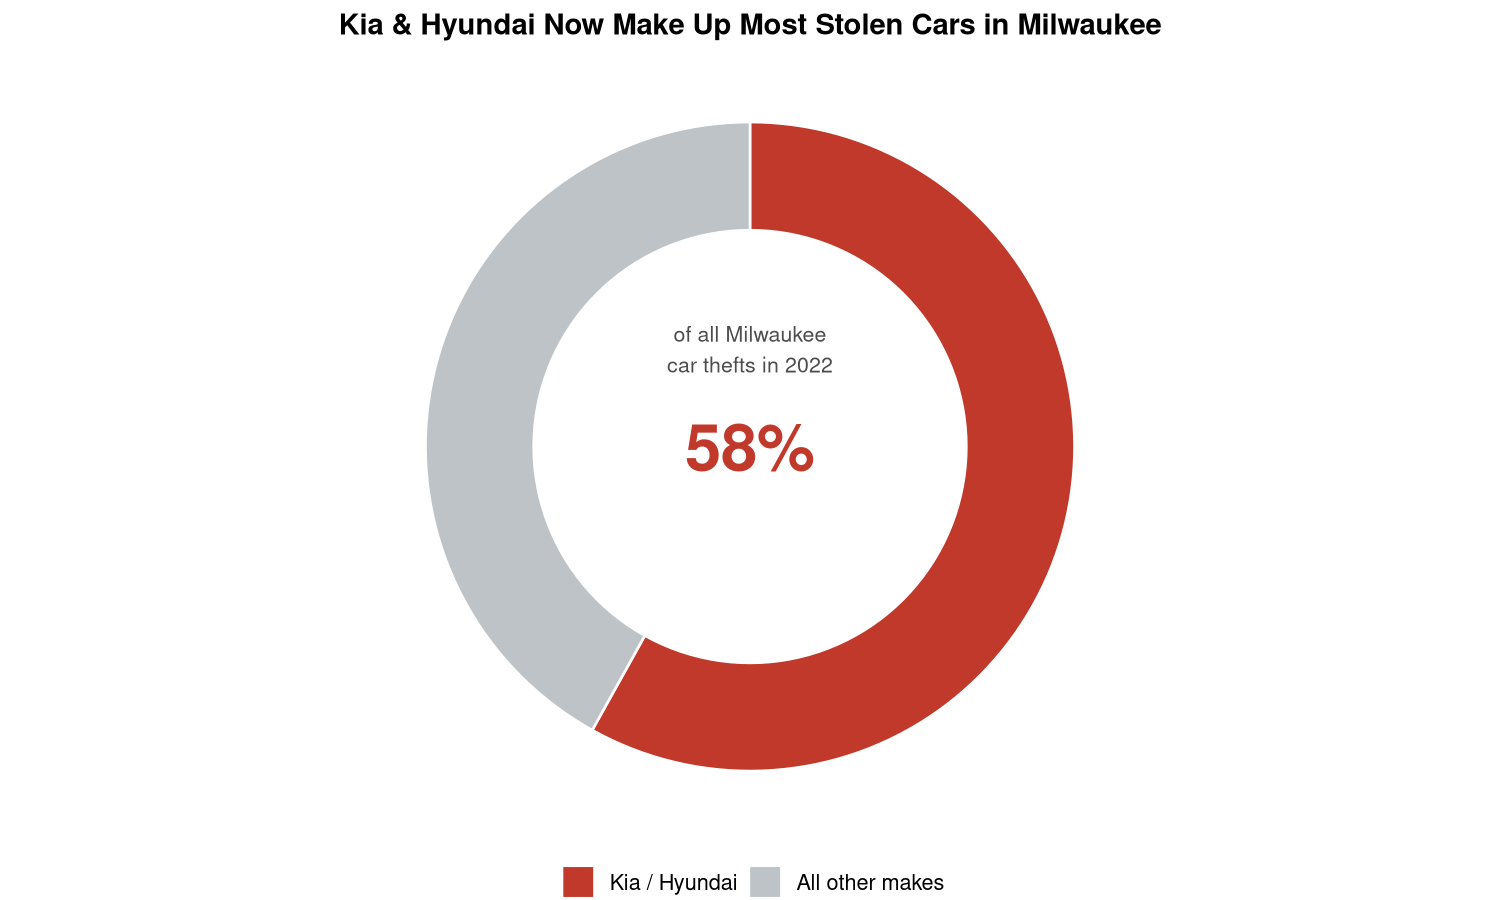

In [ ]:
# Calculate the percentage of Kia/Hyundai thefts in Milwaukee for 2022
donut_df <- milwaukee %>%
  filter(year == 2022) %>%
  summarise(KiaHyundai = sum(countKiaHyundaiThefts), Other = sum(countOtherThefts)) %>%
  pivot_longer(everything(), names_to = "group", values_to = "n") %>%
  mutate(pct = n / sum(n),
         ymax = cumsum(pct), ymin = lag(ymax, default = 0),
         group = factor(group, levels = c("KiaHyundai", "Other"),
                         labels = c("Kia / Hyundai", "All other makes")))

kh_pct <- percent(donut_df$pct[donut_df$group == "Kia / Hyundai"], accuracy = 1)

# Create the donut chart
p2 <- ggplot(donut_df, aes(ymax = ymax, ymin = ymin, xmax = 4, xmin = 3, fill = group)) +
  geom_rect(color = "white") +
  coord_polar(theta = "y") +
  xlim(c(1, 4)) +
  scale_fill_manual(values = c("Kia / Hyundai" = "#C0392B", "All other makes" = "#BDC3C7")) +
  annotate("text", x = 1, y = 0, label = kh_pct, size = 11, fontface = "bold", color = "#C0392B") +
  annotate("text", x = 1.9, y = 0, label = "of all Milwaukee\ncar thefts in 2022", size = 3.6, color = "grey30") +
  labs(title = "Kia & Hyundai Now Make Up Most Stolen Cars in Milwaukee", fill = NULL) +
  theme_void(base_size = 13) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 14),
        legend.position = "bottom")
p2

### Visual 3, Tree Map: Ranking the Hardest-Hit Cities

Using the full multi-city Motherboard/VICE workbook, this shows which metro areas absorbed the most Kia/Hyundai thefts overall. Despite being far smaller than Chicago or Los Angeles, Milwaukee ranks #2 in the nation. (There's no CRAN treemap package available in this environment, so the layout below is a small squarified-style recursive rectangle split written directly in base R, which repeatedly splits the box in the dimension that best balances the remaining totals.)

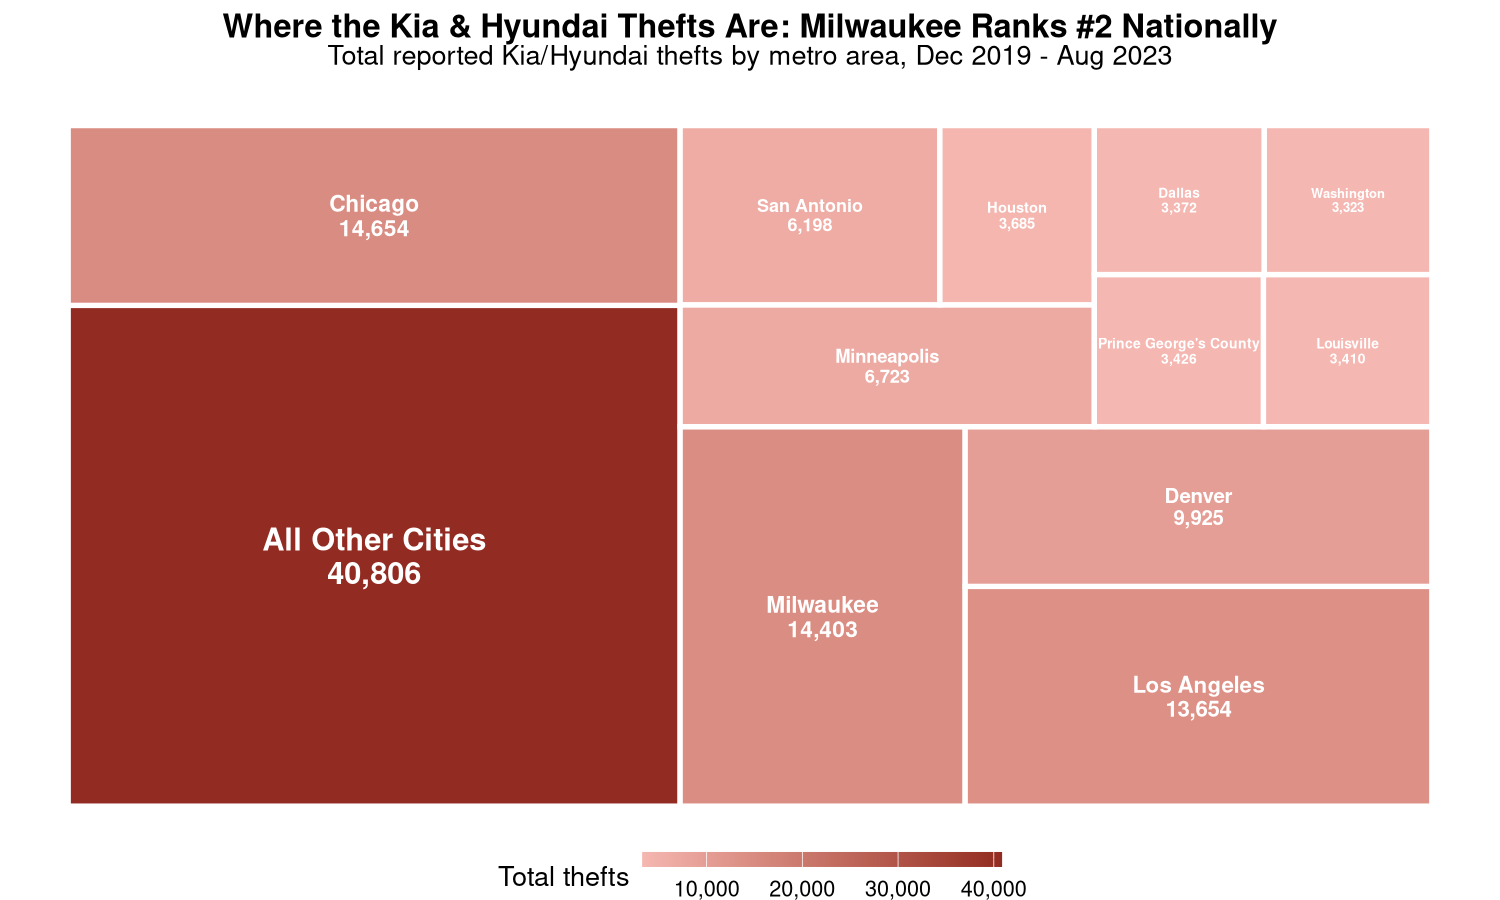

In [ ]:
# Minimal recursive "slice-and-dice" treemap layout (no external package needed)
treemap_layout <- function(df, value_col, x0 = 0, y0 = 0, w = 100, h = 100, vertical = TRUE) {
  df <- df[order(-df[[value_col]]), , drop = FALSE]
  n <- nrow(df)
  # Base cases: if no rows, return empty; if one row, assign full rectangle
  if (n == 0) return(df)
  if (n == 1) {
    df$xmin <- x0; df$xmax <- x0 + w; df$ymin <- y0; df$ymax <- y0 + h
    return(df)
  }
  # Find the index to split the data into two groups with approximately equal total values
  vals <- df[[value_col]]
  half <- sum(vals) / 2
  split_i <- which.min(abs(cumsum(vals) - half))
  split_i <- max(1, min(n - 1, split_i))
  g1 <- df[1:split_i, , drop = FALSE]
  g2 <- df[(split_i + 1):n, , drop = FALSE]
  frac1 <- sum(g1[[value_col]]) / sum(vals)
  # Recursively layout the two groups, adjusting coordinates and dimensions based on orientation
  if (vertical) {
    w1 <- w * frac1
    rbind(treemap_layout(g1, value_col, x0, y0, w1, h, FALSE),
          treemap_layout(g2, value_col, x0 + w1, y0, w - w1, h, FALSE))
  } else {
    h1 <- h * frac1
    rbind(treemap_layout(g1, value_col, x0, y0, w, h1, TRUE),
          treemap_layout(g2, value_col, x0, y0 + h1, w, h - h1, TRUE))
  }
}

# Combine the top N cities with a single "All Other Cities" row for the rest
top_n <- 11
tm_df <- city_totals %>%
  mutate(city_clean = str_remove(city, ",.*$")) %>%
  { bind_rows(
      slice_head(., n = top_n),
      summarise(slice_tail(., n = nrow(.) - top_n), city_clean = "All Other Cities", total = sum(total))
    ) } %>%
  select(city_clean, total)

# Define treemap layout and calculate label positions and areas
tm_layout <- treemap_layout(tm_df, "total") %>%
  mutate(label = paste0(city_clean, "\n", comma(total)),
         xc = (xmin + xmax) / 2, yc = (ymin + ymax) / 2,
         area = (xmax - xmin) * (ymax - ymin))

# Create a treemap of the top 10 cities by Kia/Hyundai thefts, with all others grouped together
p3 <- ggplot(tm_layout) +
  geom_rect(aes(xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, fill = total),
            color = "white", linewidth = 1.2) +
  geom_text(aes(x = xc, y = yc, label = label, size = area),
            color = "white", fontface = "bold", lineheight = 0.9, show.legend = FALSE) +
  scale_size_continuous(range = c(2.2, 5.2)) +
  scale_fill_gradient(low = "#F5B7B1", high = "#922B21", labels = comma,
                       guide = guide_colorbar(barwidth = 12, barheight = 0.5)) +
  labs(title = "Where the Kia & Hyundai Thefts Are: Milwaukee Ranks #2 Nationally",
       subtitle = "Total reported Kia/Hyundai thefts by metro area, Dec 2019 - Aug 2023",
       fill = "Total thefts") +
  theme_void(base_size = 13) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5),
        plot.subtitle = element_text(hjust = 0.5, margin = margin(b = 10)),
        legend.position = "bottom")
p3

### Visual 4, Stacked Area Chart: Milwaukee Led the Surge

Layering the top five affected cities over time shows Milwaukee led the national surge months before other cities caught up (`KiaHyundaiMilwaukeeData.csv` + `kiaHyundaiThefts.csv`).

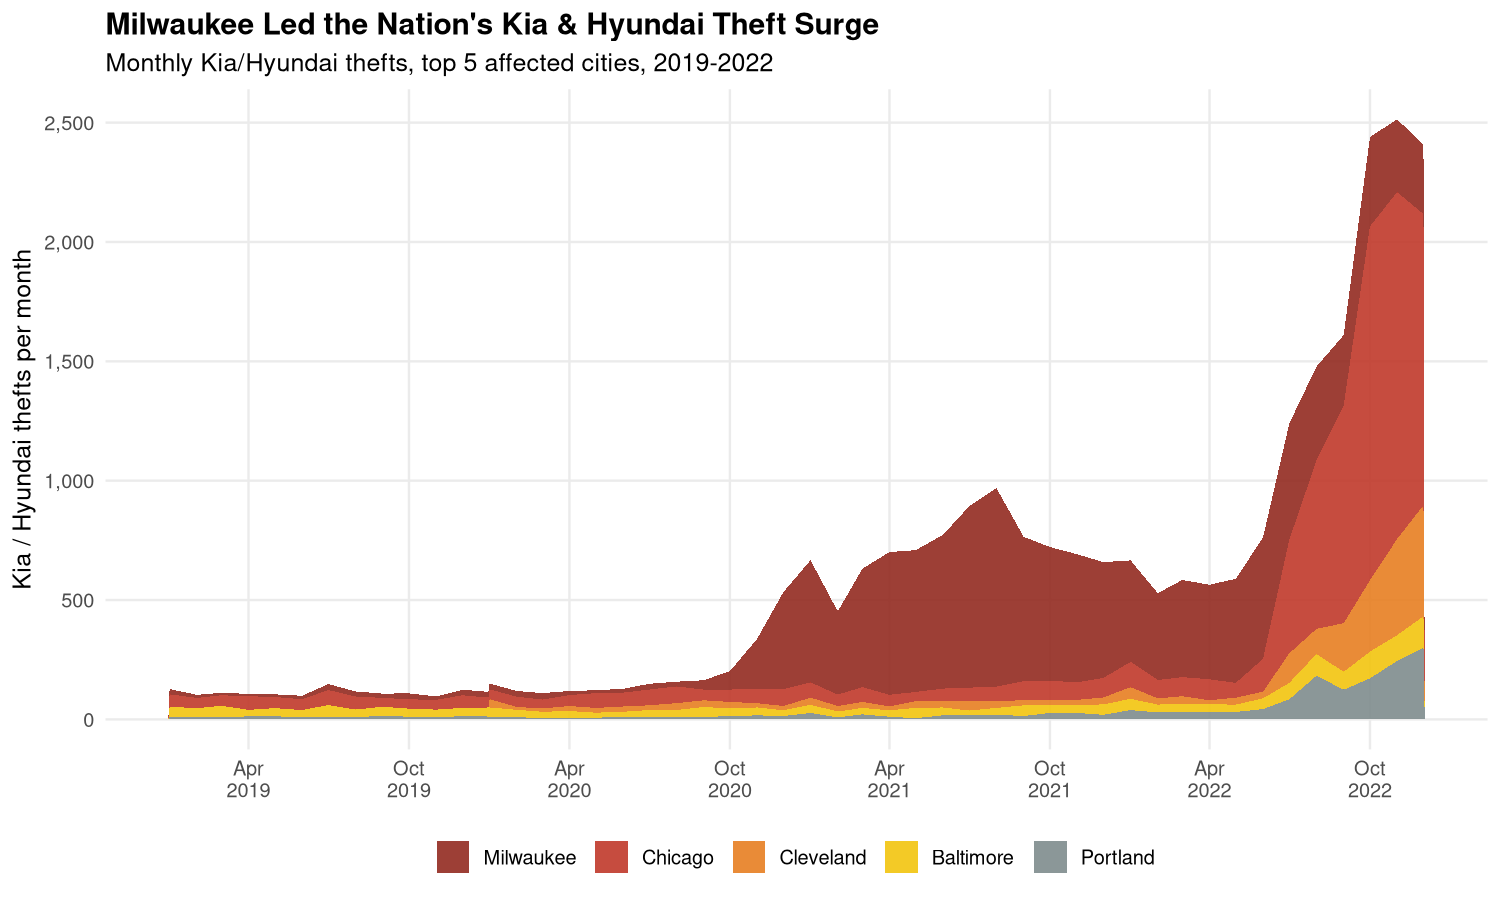

In [ ]:
# Combine Milwaukee and other cities data, create a date column, and filter for top 5 cities by total thefts
combined <- bind_rows(milwaukee, other_cities) %>%
  mutate(date = as.Date(paste(year, match(month, month_levels), "01", sep = "-")))

# Identify the top 5 cities by total Kia/Hyundai thefts
top_cities <- combined %>%
  group_by(city) %>%
  summarise(total = sum(countKiaHyundaiThefts), .groups = "drop") %>%
  arrange(desc(total)) %>%
  slice_head(n = 5) %>%
  pull(city)

# Filter for the top 5 cities and convert city to a factor
area_df <- combined %>%
  filter(city %in% top_cities) %>%
  mutate(city = factor(city, levels = top_cities))

# Create a stacked area chart of monthly Kia/Hyundai thefts for the top 5 cities
p4 <- ggplot(area_df, aes(x = date, y = countKiaHyundaiThefts, fill = city)) +
  geom_area(position = "stack", alpha = 0.9) +
  scale_fill_manual(values = c("#922B21", "#C0392B", "#E67E22", "#F1C40F", "#7F8C8D")) +
  scale_x_date(date_breaks = "6 months", date_labels = "%b\n%Y") +
  scale_y_continuous(labels = comma) +
  labs(title = "Milwaukee Led the Nation's Kia & Hyundai Theft Surge",
       subtitle = "Monthly Kia/Hyundai thefts, top 5 affected cities, 2019-2022",
       x = NULL, y = "Kia / Hyundai thefts per month", fill = NULL) +
  theme(plot.title = element_text(face = "bold"), legend.position = "bottom",
        panel.grid.minor = element_blank())
p4

### Visual 5, Area Chart: Milwaukee's Trend Alone

Milwaukee's monthly count on its own lines up almost exactly with when the "Kia Challenge" went viral on TikTok in mid-2021.

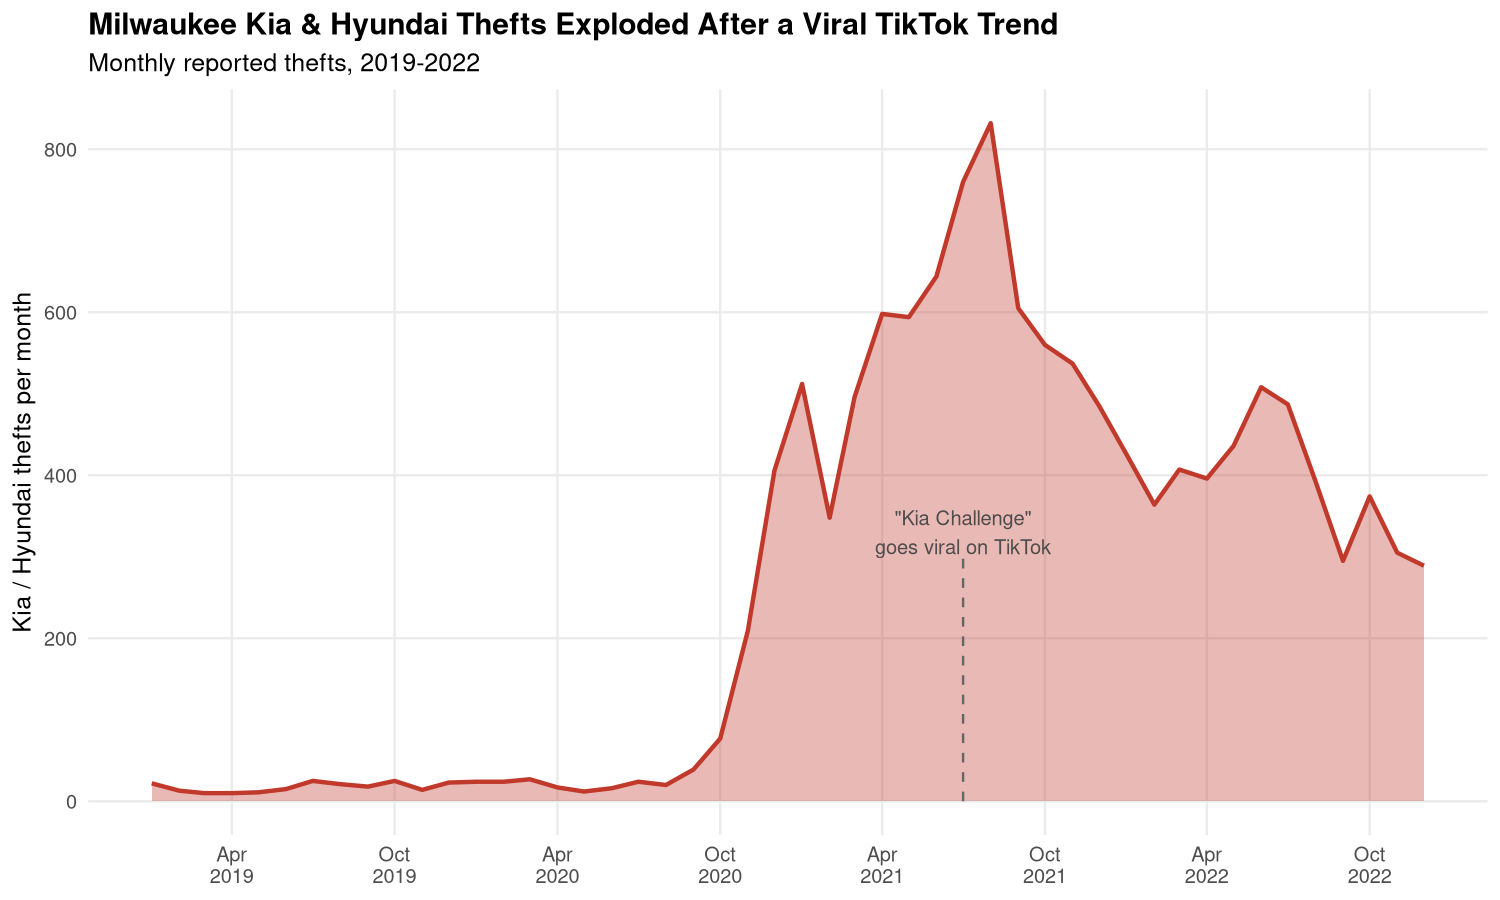

In [ ]:
# Create focused area chart for Milwaukee, highlighting TikTok trend
p5 <- ggplot(milwaukee, aes(x = date, y = countKiaHyundaiThefts)) +
  geom_area(fill = "#C0392B", alpha = 0.35) +
  geom_line(color = "#C0392B", linewidth = 1) +
  annotate("segment", x = as.Date("2021-07-01"), xend = as.Date("2021-07-01"), y = 0, yend = 300,
           linetype = "dashed", color = "grey40") +
  annotate("text", x = as.Date("2021-07-01"), y = 330,
           label = "\"Kia Challenge\"\ngoes viral on TikTok", size = 3.4, color = "grey30", hjust = 0.5) +
  scale_x_date(date_breaks = "6 months", date_labels = "%b\n%Y") +
  scale_y_continuous(labels = comma) +
  labs(title = "Milwaukee Kia & Hyundai Thefts Exploded After a Viral TikTok Trend",
       subtitle = "Monthly reported thefts, 2019-2022", x = NULL, y = "Kia / Hyundai thefts per month") +
  theme(plot.title = element_text(face = "bold"), panel.grid.minor = element_blank())
p5

### Visual 6, Stacked Bar Chart: Only One Slice Is Moving

Thefts of every other make stayed roughly flat year over year in Milwaukee, while only the Kia/Hyundai slice moved. That's exactly why a vehicle-specific fix (software patch + steering-wheel lock), not a general anti-crime push, is the right response.

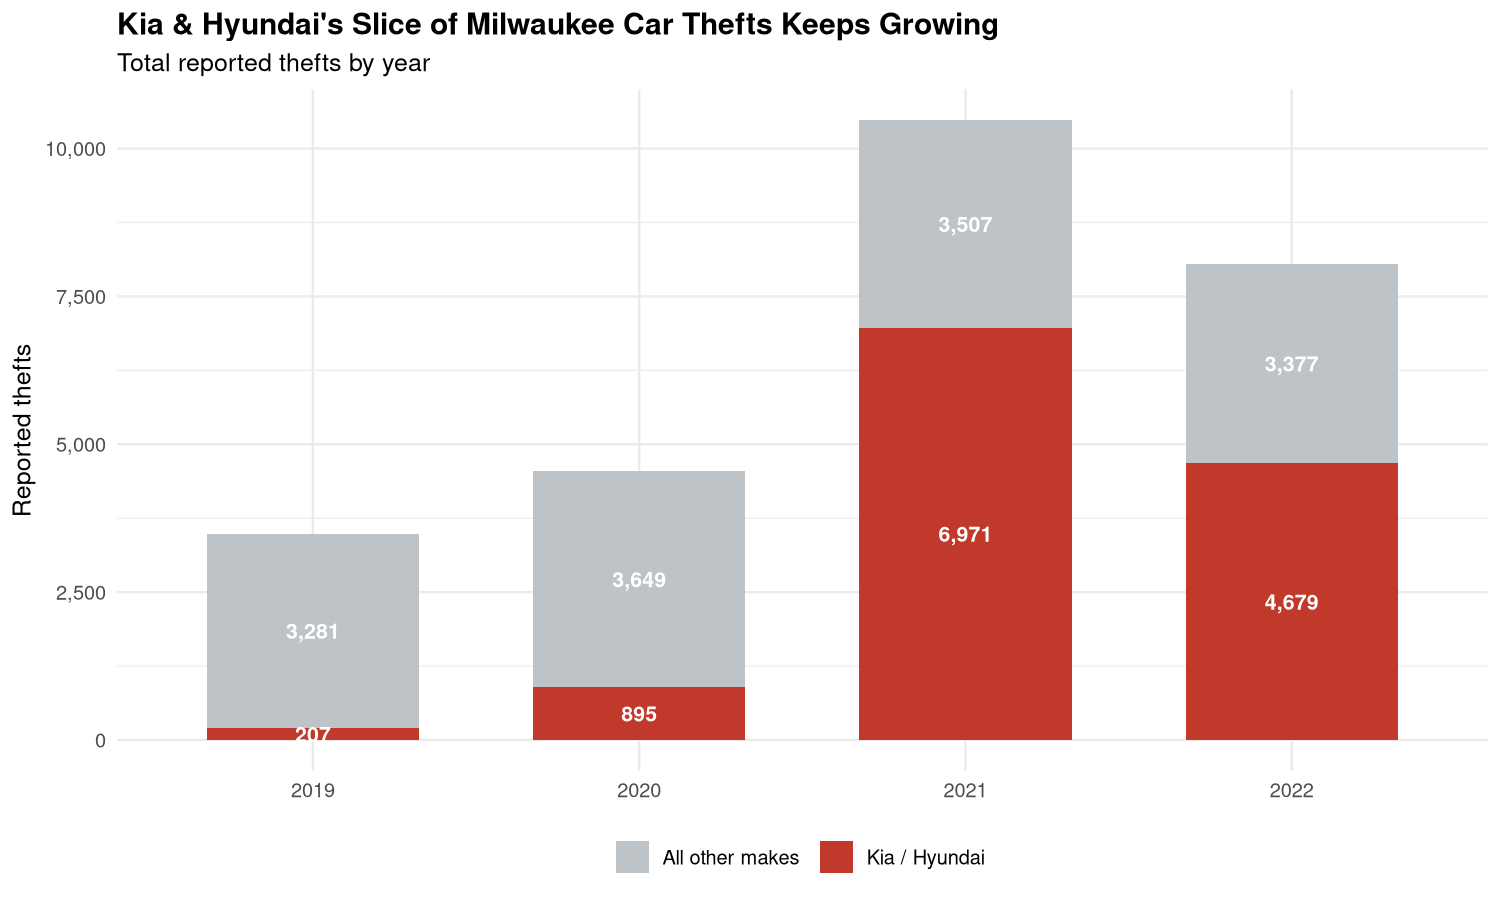

In [ ]:
# Group by year, summarize total thefts, then pivot to long format
bar_df <- milwaukee %>%
  group_by(year) %>%
  summarise(KiaHyundai = sum(countKiaHyundaiThefts), Other = sum(countOtherThefts), .groups = "drop") %>%
  pivot_longer(-year, names_to = "group", values_to = "n") %>%
  mutate(group = factor(group, levels = c("Other", "KiaHyundai"), labels = c("All other makes", "Kia / Hyundai")))

# Create the stacked bar chart
p6 <- ggplot(bar_df, aes(x = factor(year), y = n, fill = group)) +
  geom_col(position = "stack", width = 0.65) +
  geom_text(aes(label = comma(n)), position = position_stack(vjust = 0.5),
            color = "white", size = 3.6, fontface = "bold") +
  scale_fill_manual(values = c("All other makes" = "#BDC3C7", "Kia / Hyundai" = "#C0392B")) +
  scale_y_continuous(labels = comma) +
  labs(title = "Kia & Hyundai's Slice of Milwaukee Car Thefts Keeps Growing",
       subtitle = "Total reported thefts by year", x = NULL, y = "Reported thefts", fill = NULL) +
  theme(plot.title = element_text(face = "bold"), legend.position = "bottom")
p6

## Call to Action

If you or someone you know drives an affected Kia or Hyundai in Milwaukee: get the free anti-theft software update at any dealership, and pick up a free steering wheel lock at your local MPD district station. If you're in a position to fund or extend the giveaway program, the data above is the case for why it's worth it.

## Written Summary

**Audience.** This story targets Milwaukee area Kia and Hyundai owners and the general Milwaukee public, not analysts or city officials. I'm assuming low familiarity with crime statistics and no prior knowledge of the "Kia Boyz" TikTok trend, so the visuals are built to stand on their own with a plain-language headline instead of a technical axis label.

**Purpose.** This is not a general "crime is rising" story. The data shows overall car theft climbed at 4 in 5 agencies nationwide, but Kia and Hyundai thefts specifically exploded far beyond that baseline, driven by a single fixable vulnerability (missing engine immobilizers, exploited via a viral 2022 TikTok method). The call to action is concrete: get the free dealer software patch and a free steering wheel lock from MPD, and keep funding the giveaway program since it targets the actual mechanism of the crime rather than crime in general.

**Medium.** I designed this as a visual-first explainer meant to work as a social carousel or a one page flyer, something read in the time it takes to scroll past a post or wait in a police station lobby, not a dashboard built for analysts.

**Design.** Every chart uses the same color grammar: red always means "Kia/Hyundai," gray always means "everything else," so a reader who has seen one chart can instantly parse the next one (similarity). Labels sit on or beside their data instead of in a separate legend, cutting down the back-and-forth eye movement between a legend and the plot (proximity). Titles are written as the takeaway ("Milwaukee Ranks #2 Nationally") rather than a description of the chart, and every chart keeps generous white space and a single accent color so the red segment reads as the clear figure against a muted ground.

**Ethical considerations.** All four provided datasets are aggregated, public, agency- or newsroom-sourced counts with no personally identifiable information, so acquisition itself carries little risk. A few transformations are worth disclosing: I reshaped the irregular Motherboard/VICE workbook (city names written once per 3-column block, with blank cells beside them) into a tidy table, and in the tree map I collapsed 59 smaller cities into a single "All Other Cities" bucket for readability which is labeled directly on the chart. Because reporting coverage differs by agency and year (some cells are simply missing), all totals are undercounts rather than a full census, and I did not impute missing months as zero, since doing so would understate risk in cities with gaps. The bigger ethical risk is framing: a story like this can slide into stigmatizing Kia/Hyundai owners as easy targets, or Milwaukee as uniquely unsafe. I mitigated that by pairing every "this is bad" chart with a specific, low cost, non-punitive remedy, and by keeping every visual at the city level (never neighborhood or address level) so nothing here could be used to target a specific area or individual.